In [38]:
import os
import random
import json
import time
import zipfile
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.amp import autocast, GradScaler
from tqdm import tqdm
from huggingface_hub import login, hf_hub_download
from kaggle_secrets import UserSecretsClient
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Whitespace

# ==========================================
# 1. Setup, Configuration & Authentication
# ==========================================
user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
# TRAIN_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TEST_FILE = "Phase_1_Pretraining/Test/Phase1-Test.json"

PROPORTIONS = {
    "train_supreme_court.json": 0.45,
    "train_high_courts.json": 0.30,
    "train_acts.json": 0.15,
    "train_tribunals.json": 0.10
}

# Hyperparameters
TRAIN_TOKENS = 150_000_000  # Adjust based on your time constraints
VAL_TOKENS = 4_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 1
SEED = 42
random.seed(SEED)

# Custom Model Dimensions (~50M params)
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 512
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4 
VOCAB_SIZE = 32000

# Training Optimizations (2x T4 specific)
BATCH_SIZE = 2       # Scaled up for dual GPUs
ACCUMULATION_STEPS = 16 # Effective batch size = 32

# Generation Config
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.1
TOP_P = 0.95

# Paths
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-custom-final")
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "latest_checkpoint.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
os.makedirs(OUTPUT_DIR, exist_ok=True)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


CUDA available: True
GPU count: 2


In [3]:
data_files = {}
for filename in PROPORTIONS.keys():
    print(f"Downloading {filename}...")
    # The training files are located in the Phase_1_Pretraining/Train/ directory
    file_path = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=f"Phase_1_Pretraining/Train/{filename}",
        repo_type="dataset",
        token=HF_TOKEN
    )
    data_files[filename] = file_path

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_high_cou(…):   0%|          | 0.00/10.7G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_acts.jso(…):   0%|          | 0.00/729M [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_tribunal(…):   0%|          | 0.00/6.48G [00:00<?, ?B/s]

In [4]:
# # ==========================================
# # 2. Download Data & Train BPE Tokenizer
# # ==========================================
# print("Downloading training data...")
# train_file_path = hf_hub_download(
#     repo_id=HF_DATASET_REPO,
#     filename=TRAIN_FILE,
#     repo_type="dataset",
#     token=HF_TOKEN
# )

# with open(train_file_path, "r", encoding="utf-8") as f:
#     records = json.load(f)

# # The dataset format is {"1": {"text": "..."}}
# text_corpus = [data["text"] for data in records.values() if "text" in data]

# print("Training Custom BPE Tokenizer...")
# tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
# tokenizer.pre_tokenizer = Whitespace()
# trainer = BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=["[UNK]", "[PAD]", "[BOS]", "[EOS]"])
# tokenizer.train_from_iterator(text_corpus, trainer=trainer)
# tokenizer.save(os.path.join(OUTPUT_DIR, "custom_bpe.json"))

In [39]:
import json
import os
import random
from collections import Counter, defaultdict

class CustomScratchBPE:
    def __init__(self, vocab_size, special_tokens=None):
        self.vocab_size = vocab_size
        self.special_tokens = special_tokens or ["[UNK]", "[PAD]", "[BOS]", "[EOS]"]
        self.vocab = {}       
        self.inv_vocab = {}   
        self.merges = {}      
        
    def train(self, text_list):
        print("Aggregating and filtering word frequencies...")
        word_freqs = Counter()
        
        for text in text_list:
            words = ["Ġ" + w for w in text.split() if w and len(w) <= 35]
            word_freqs.update(words)
            
        # Drop singletons to save RAM
        word_freqs = Counter({word: freq for word, freq in word_freqs.items() if freq > 1})
        print(f"Unique words after filtering singletons: {len(word_freqs):,}")
            
        unique_chars = set()
        for word in word_freqs:
            unique_chars.update(list(word))
            
        idx = 0
        for st in self.special_tokens:
            self.vocab[st] = idx
            self.inv_vocab[idx] = st
            idx += 1
            
        for ch in sorted(list(unique_chars)):
            self.vocab[ch] = idx
            self.inv_vocab[idx] = ch
            idx += 1
            
        splits = {word: [self.vocab[c] for c in word] for word in word_freqs}
        target_merges = self.vocab_size - len(self.vocab)
        print(f"Base character vocab size: {len(self.vocab)}. Target merges: {target_merges}")
        
        # ---------------------------------------------------------
        # SPEED OPTIMIZATION: Initial Pair Counts & Inverted Index
        # ---------------------------------------------------------
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j+1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)

        for i in range(target_merges):
            if not pair_counts:
                break
                
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = idx
            idx += 1
            
            self.merges[best_pair] = new_id
            new_token_str = self.inv_vocab[best_pair[0]] + self.inv_vocab[best_pair[1]]
            self.vocab[new_token_str] = new_id
            self.inv_vocab[new_id] = new_token_str
            
            # ---------------------------------------------------------
            # FAST INCREMENTAL UPDATE: Only modify words containing best_pair
            # ---------------------------------------------------------
            words_to_update = list(pair_to_words.get(best_pair, []))
            
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                
                # 1. Remove old pairs from global tracking for this word
                for j in range(len(split) - 1):
                    pair = (split[j], split[j+1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words[pair]:
                            pair_to_words[pair].remove(word)

                # 2. Perform the merge on this word's split
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j+1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split

                # 3. Add newly created pairs to global tracking for this word
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j+1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
                
            if (i + 1) % 500 == 0:
                print(f"Completed {i + 1}/{target_merges} merges...")

    def encode(self, text):
        words = ["Ġ" + w for w in text.split() if w and len(w) <= 35]
        tokens = []
        unk_id = self.vocab.get("[UNK]", 0)
        
        for word in words:
            split = [self.vocab.get(c, unk_id) for c in word]
            while len(split) > 1:
                min_idx = -1
                min_rank = float('inf')
                for i in range(len(split) - 1):
                    pair = (split[i], split[i+1])
                    if pair in self.merges:
                        rank = self.merges[pair]
                        if rank < min_rank:
                            min_rank = rank
                            min_idx = i
                if min_idx == -1:
                    break
                pair = (split[min_idx], split[min_idx+1])
                new_id = self.merges[pair]
                split = split[:min_idx] + [new_id] + split[min_idx+2:]
            tokens.extend(split)
        return tokens

    def decode(self, token_ids):
        text = "".join(self.inv_vocab.get(t, "[UNK]") for t in token_ids)
        return text.replace("Ġ", " ").strip()

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f"{k[0]},{k[1]}": v for k, v in self.merges.items()}
        data = {"vocab": self.vocab, "merges": serializable_merges, "special_tokens": self.special_tokens}
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False, indent=2)

    def load(self, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        self.vocab = data["vocab"]
        self.inv_vocab = {v: k for k, v in self.vocab.items()}
        self.special_tokens = data["special_tokens"]
        self.merges = {tuple(map(int, k.split(","))): v for k, v in data["merges"].items()}


# ==========================================
# 2. Streaming Sample Extraction & BPE Training
# ==========================================
# ==========================================
# 2. Load or Train BPE Tokenizer
# ==========================================
tokenizer_path = os.path.join(OUTPUT_DIR, "custom_bpe_scratch.json")

tokenizer = CustomScratchBPE(vocab_size=32000)

if os.path.exists(tokenizer_path):
    print(f"Loading existing tokenizer from {tokenizer_path}...")
    tokenizer.load(tokenizer_path)
    print(f"Loaded Vocabulary size: {tokenizer.get_vocab_size()}")
else:
    print("Streaming subset for tokenizer training...")
    text_corpus_for_tokenizer = []

    for filename, filepath in data_files.items():
        print(f"Adding from {filename}")
        records = []
        
        with open(filepath, "r", encoding="utf-8") as f:
            first_char = f.read(1)
            f.seek(0)
            
            if first_char != '[':
                for i, line in enumerate(f):
                    if i > 5000: break
                    try:
                        obj = json.loads(line)
                        if isinstance(obj, dict) and "text" in obj:
                            records.append(obj)
                    except:
                        continue
            else:
                for line in f:
                    if len(records) >= 2000: break
                    try:
                        obj = json.loads(line.strip().strip(','))
                        if isinstance(obj, dict) and "text" in obj:
                            records.append(obj)
                    except:
                        continue

        if records:
            sample_docs = random.sample(records, min(1000, len(records)))
            text_corpus_for_tokenizer.extend([d["text"] for d in sample_docs if "text" in d])

    print("Training Custom BPE Tokenizer from scratch (Optimized Incremental)...")
    tokenizer.train(text_corpus_for_tokenizer)
    tokenizer.save(tokenizer_path)
    print(f"Final Vocabulary size: {tokenizer.get_vocab_size()}")

Loading existing tokenizer from /kaggle/working/cs781_phase1/custom_bpe_scratch.json...
Loaded Vocabulary size: 32000


In [6]:
# import json
# import os
# import random
# from collections import Counter, defaultdict

# class CustomScratchBPE:
#     def __init__(self, vocab_size, special_tokens=None):
#         self.vocab_size = vocab_size
#         self.special_tokens = special_tokens or ["[UNK]", "[PAD]", "[BOS]", "[EOS]"]
#         self.vocab = {}       
#         self.inv_vocab = {}   
#         self.merges = {}      
        
#     def train(self, text_list):
#         print("Aggregating and filtering word frequencies...")
#         word_freqs = Counter()
        
#         for text in text_list:
#             words = ["Ġ" + w for w in text.split() if w and len(w) <= 35]#See this again
#             word_freqs.update(words)
            
#         # Drop singletons to save RAM
#         word_freqs = Counter({word: freq for word, freq in word_freqs.items() if freq > 1})
#         print(f"Unique words after filtering singletons: {len(word_freqs):,}")
            
#         unique_chars = set()
#         for word in word_freqs:
#             unique_chars.update(list(word))
            
#         idx = 0
#         for st in self.special_tokens:
#             self.vocab[st] = idx
#             self.inv_vocab[idx] = st
#             idx += 1
            
#         for ch in sorted(list(unique_chars)):
#             self.vocab[ch] = idx
#             self.inv_vocab[idx] = ch
#             idx += 1
            
#         splits = {word: [self.vocab[c] for c in word] for word in word_freqs}
#         target_merges = self.vocab_size - len(self.vocab)
#         print(f"Base character vocab size: {len(self.vocab)}. Target merges: {target_merges}")
        
#         for i in range(target_merges):
#             pair_counts = defaultdict(int)
#             for word, freq in word_freqs.items():
#                 split = splits[word]
#                 for j in range(len(split) - 1):
#                     pair_counts[(split[j], split[j+1])] += freq
                    
#             if not pair_counts:
#                 break
                
#             best_pair = max(pair_counts, key=pair_counts.get)
#             new_id = idx
#             idx += 1
            
#             self.merges[best_pair] = new_id
#             new_token_str = self.inv_vocab[best_pair[0]] + self.inv_vocab[best_pair[1]]
#             self.vocab[new_token_str] = new_id
#             self.inv_vocab[new_id] = new_token_str
            
#             for word in splits:
#                 split = splits[word]
#                 if len(split) < 2:
#                     continue
#                 new_split = []
#                 j = 0
#                 while j < len(split):
#                     if j < len(split) - 1 and (split[j], split[j+1]) == best_pair:
#                         new_split.append(new_id)
#                         j += 2
#                     else:
#                         new_split.append(split[j])
#                         j += 1
#                 splits[word] = new_split
                
#             if (i + 1) % 100 == 0:
#                 print(f"Completed {i + 1}/{target_merges} merges...")

#     def encode(self, text):
#         words = ["Ġ" + w for w in text.split() if w and len(w) <= 35]
#         tokens = []
#         unk_id = self.vocab.get("[UNK]", 0)
        
#         for word in words:
#             split = [self.vocab.get(c, unk_id) for c in word]
#             while len(split) > 1:
#                 min_idx = -1
#                 min_rank = float('inf')
#                 for i in range(len(split) - 1):
#                     pair = (split[i], split[i+1])
#                     if pair in self.merges:
#                         rank = self.merges[pair]
#                         if rank < min_rank:
#                             min_rank = rank
#                             min_idx = i
#                 if min_idx == -1:
#                     break
#                 pair = (split[min_idx], split[min_idx+1])
#                 new_id = self.merges[pair]
#                 split = split[:min_idx] + [new_id] + split[min_idx+2:]
#             tokens.extend(split)
#         return tokens

#     def decode(self, token_ids):
#         text = "".join(self.inv_vocab.get(t, "[UNK]") for t in token_ids)
#         return text.replace("Ġ", " ").strip()

#     def get_vocab_size(self):
#         return len(self.vocab)

#     def save(self, path):
#         serializable_merges = {f"{k[0]},{k[1]}": v for k, v in self.merges.items()}
#         data = {"vocab": self.vocab, "merges": serializable_merges, "special_tokens": self.special_tokens}
#         with open(path, "w", encoding="utf-8") as f:
#             json.dump(data, f, ensure_ascii=False, indent=2)

#     def load(self, path):
#         with open(path, "r", encoding="utf-8") as f:
#             data = json.load(f)
#         self.vocab = data["vocab"]
#         self.inv_vocab = {v: k for k, v in self.vocab.items()}
#         self.special_tokens = data["special_tokens"]
#         self.merges = {tuple(map(int, k.split(","))): v for k, v in data["merges"].items()}


# # ==========================================
# # 2. Streaming Sample Extraction & BPE Training
# # ==========================================
# print("Streaming subset for tokenizer training...")
# text_corpus_for_tokenizer = []

# for filename, filepath in data_files.items():
#     print(f"Adding from {filename}")
#     records = []
    
#     with open(filepath, "r", encoding="utf-8") as f:
#         first_char = f.read(1)
#         f.seek(0)
        
#         # If it's a JSONL file (one JSON object per line)
#         if first_char != '[':
#             for i, line in enumerate(f):
#                 if i > 5000: break # Read first 5000 lines max
#                 try:
#                     obj = json.loads(line)
#                     if isinstance(obj, dict) and "text" in obj:
#                         records.append(obj)
#                 except:
#                     continue
#         else:
#             # If it's a massive JSON array file, we can read chunks safely 
#             # or use standard line evaluation if formatted line-by-line.
#             # To avoid syntax crashes on multi-line JSON arrays, read lines and try parsing:
#             buffer = ""
#             for line in f:
#                 buffer += line
#                 if len(buffer) > 5_000_000: # Read up to ~5MB chunks
#                     break
#             # Try parsing a safe substring or use standard line-by-line fallback
#             for line in f:
#                 if len(records) >= 2000: break
#                 try:
#                     obj = json.loads(line.strip().strip(','))
#                     if isinstance(obj, dict) and "text" in obj:
#                         records.append(obj)
#                 except:
#                     continue

#     if records:
#         sample_docs = random.sample(records, min(1000, len(records)))
#         text_corpus_for_tokenizer.extend([d["text"] for d in sample_docs if "text" in d])
#     else:
#         print(f"Warning: No records extracted from {filename}. Check JSON format.")

# print("Training Custom BPE Tokenizer from scratch...")
# tokenizer = CustomScratchBPE(vocab_size=32000)
# tokenizer.train(text_corpus_for_tokenizer)
# tokenizer.save(os.path.join(OUTPUT_DIR, "custom_bpe_scratch.json"))
# print(f"Final Vocabulary size: {tokenizer.get_vocab_size()}")

In [7]:
# import json
# import os
# import random
# from collections import Counter, defaultdict

# class CustomScratchBPE:
#     def __init__(self, vocab_size, special_tokens=None):
#         self.vocab_size = vocab_size
#         self.special_tokens = special_tokens or ["[UNK]", "[PAD]", "[BOS]", "[EOS]"]
#         self.vocab = {}       
#         self.inv_vocab = {}   
#         self.merges = {}      
        
#     def train(self, text_list):
#         print("Aggregating word frequencies...")
#         word_freqs = Counter()
#         for text in text_list:
#             words = ["Ġ" + w for w in text.split()]
#             word_freqs.update(words)
            
#         # ---------------------------------------------------------
#         # MEMORY FIX: Drop words that appear only once (frequency == 1).
#         # This cuts memory usage by 70-80% instantly without hurting BPE quality.
#         # ---------------------------------------------------------
#         print(f"Unique words before filtering: {len(word_freqs):,}")
#         word_freqs = Counter({word: freq for word, freq in word_freqs.items() if freq > 1})
#         print(f"Unique words after filtering singletons: {len(word_freqs):,}")

#         unique_chars = set()
#         for word in word_freqs:
#             unique_chars.update(list(word))
            
#         idx = 0
#         for st in self.special_tokens:
#             self.vocab[st] = idx
#             self.inv_vocab[idx] = st
#             idx += 1
            
#         for ch in sorted(list(unique_chars)):
#             self.vocab[ch] = idx
#             self.inv_vocab[idx] = ch
#             idx += 1
            
#         splits = {word: [self.vocab[c] for c in word] for word in word_freqs}
#         target_merges = self.vocab_size - len(self.vocab)
#         print(f"Base character vocab size: {len(self.vocab)}. Target merges: {target_merges}")
        
#         for i in range(target_merges):
#             pair_counts = defaultdict(int)
#             for word, freq in word_freqs.items():
#                 split = splits[word]
#                 for j in range(len(split) - 1):
#                     pair_counts[(split[j], split[j+1])] += freq
                    
#             if not pair_counts:
#                 break
                
#             best_pair = max(pair_counts, key=pair_counts.get)
#             new_id = idx
#             idx += 1
            
#             self.merges[best_pair] = new_id
#             new_token_str = self.inv_vocab[best_pair[0]] + self.inv_vocab[best_pair[1]]
#             self.vocab[new_token_str] = new_id
#             self.inv_vocab[new_id] = new_token_str
            
#             # Memory-safe lightweight sweep
#             for word in splits:
#                 split = splits[word]
#                 if len(split) < 2:
#                     continue
#                 new_split = []
#                 j = 0
#                 while j < len(split):
#                     if j < len(split) - 1 and (split[j], split[j+1]) == best_pair:
#                         new_split.append(new_id)
#                         j += 2
#                     else:
#                         new_split.append(split[j])
#                         j += 1
#                 splits[word] = new_split
                
#             if (i + 1) % 1000 == 0:
#                 print(f"Completed {i + 1}/{target_merges} merges...")

#     def encode(self, text):
#         words = ["Ġ" + w for w in text.split()]
#         tokens = []
#         unk_id = self.vocab.get("[UNK]", 0)
        
#         for word in words:
#             split = [self.vocab.get(c, unk_id) for c in word]
#             while len(split) > 1:
#                 min_idx = -1
#                 min_rank = float('inf')
#                 for i in range(len(split) - 1):
#                     pair = (split[i], split[i+1])
#                     if pair in self.merges:
#                         rank = self.merges[pair]
#                         if rank < min_rank:
#                             min_rank = rank
#                             min_idx = i
#                 if min_idx == -1:
#                     break
#                 pair = (split[min_idx], split[min_idx+1])
#                 new_id = self.merges[pair]
#                 split = split[:min_idx] + [new_id] + split[min_idx+2:]
#             tokens.extend(split)
#         return tokens

#     def decode(self, token_ids):
#         text = "".join(self.inv_vocab.get(t, "[UNK]") for t in token_ids)
#         return text.replace("Ġ", " ").strip()

#     def get_vocab_size(self):
#         return len(self.vocab)

#     def save(self, path):
#         serializable_merges = {f"{k[0]},{k[1]}": v for k, v in self.merges.items()}
#         data = {"vocab": self.vocab, "merges": serializable_merges, "special_tokens": self.special_tokens}
#         with open(path, "w", encoding="utf-8") as f:
#             json.dump(data, f, ensure_ascii=False, indent=2)

#     def load(self, path):
#         with open(path, "r", encoding="utf-8") as f:
#             data = json.load(f)
#         self.vocab = data["vocab"]
#         self.inv_vocab = {v: k for k, v in self.vocab.items()}
#         self.special_tokens = data["special_tokens"]
#         self.merges = {tuple(map(int, k.split(","))): v for k, v in data["merges"].items()}

# # ==========================================
# # 2. Download Data & Train BPE Tokenizer
# # ==========================================
# print("Extracting subset for tokenizer training...")
# text_corpus_for_tokenizer = []

# for filename, filepath in data_files.items():
#     with open(filepath, "r", encoding="utf-8") as f:
#         records = json.load(f)
        
#         # FIX: Since records is already a list, we can sample it directly
#         sample_docs = random.sample(records, min(1000, len(records)))
        
#         text_corpus_for_tokenizer.extend([d["text"] for d in sample_docs if "text" in d])
#     print("Done")

# print("Training Custom BPE Tokenizer from scratch (Optimized Memory)...")
# tokenizer = CustomScratchBPE(vocab_size=32000)
# tokenizer.train(text_corpus_for_tokenizer)
# tokenizer.save(os.path.join(OUTPUT_DIR, "custom_bpe_scratch.json"))
# print(f"Final Vocabulary size: {tokenizer.get_vocab_size()}")

In [8]:
# # ==========================================
# # 3. Create Datasets & DataLoaders
# # ==========================================
# train_tokens = []
# val_tokens = []

# for text in text_corpus:
#     tokens = tokenizer.encode(text).ids
#     if random.random() < 0.05:
#         if len(val_tokens) < VAL_TOKENS:
#             val_tokens.extend(tokens[:(VAL_TOKENS - len(val_tokens))])
#     else:
#         if len(train_tokens) < TRAIN_TOKENS:
#             train_tokens.extend(tokens[:(TRAIN_TOKENS - len(train_tokens))])
            
#     if len(train_tokens) >= TRAIN_TOKENS and len(val_tokens) >= VAL_TOKENS:
#         break

# def create_blocks(tokens, block_size):
#     total_length = (len(tokens) // block_size) * block_size
#     return [tokens[i:i + block_size] for i in range(0, total_length, block_size)]

# class BlockDataset(torch.utils.data.Dataset):
#     def __init__(self, blocks):
#         self.blocks = torch.tensor(blocks, dtype=torch.long)
#     def __len__(self):
#         return len(self.blocks)
#     def __getitem__(self, idx):
#         return self.blocks[idx, :-1], self.blocks[idx, 1:]

# train_loader = torch.utils.data.DataLoader(
#     BlockDataset(create_blocks(train_tokens, TRAIN_BLOCK_SIZE)), 
#     batch_size=BATCH_SIZE, 
#     shuffle=True, 
#     pin_memory=True,  # Optimizes CPU->GPU transfer
#     num_workers=2     # Utilizes Kaggle CPU cores
# )
# val_loader = torch.utils.data.DataLoader(
#     BlockDataset(create_blocks(val_tokens, TRAIN_BLOCK_SIZE)), 
#     batch_size=BATCH_SIZE,
#     pin_memory=True
# )

In [9]:
# ==========================================
# 3. Tokenization & Dataset Creation (Streaming & Zero-Memory Overhead)
# ==========================================
print("Processing and mixing tokens via streaming...")

# Pre-allocate 1D PyTorch Tensors for training and validation tokens
train_tokens_tensor = torch.zeros(TRAIN_TOKENS + TRAIN_BLOCK_SIZE, dtype=torch.long,device='cpu')
val_tokens_tensor = torch.zeros(VAL_TOKENS + TRAIN_BLOCK_SIZE, dtype=torch.long,device='cpu')

current_train = 0
current_val = 0

for filename, filepath in data_files.items():
    weight = PROPORTIONS[filename]
    target_train = int(TRAIN_TOKENS * weight)
    target_val = int(VAL_TOKENS * weight)
    file_train = 0
    file_val = 0
    
    print(f"Tokenizing and streaming from {filename}...")
    with open(filepath, "r", encoding="utf-8") as f:
        first_char = f.read(1)
        f.seek(0)
        
        # Stream file line-by-line depending on format to protect RAM
        for i, line in enumerate(f):
            if i % 15000 == 0 and i > 0:
                print(f"[{filename}] Processed {i:,} lines... (Train: {file_train:,} | Val: {file_val:,})")

            if file_train >= target_train and file_val >= target_val:
                break
                
            try:
                if first_char != '[':
                    data = json.loads(line)
                else:
                    # Clean commas for line-by-line JSON array parsing
                    stripped = line.strip().rstrip(',')
                    if stripped in ('[', ']'):
                        continue
                    data = json.loads(stripped)
            except:
                continue
                
            if not isinstance(data, dict) or "text" not in data:
                continue
                
            tokens = tokenizer.encode(data["text"])
            if not tokens:
                continue
                
            tok_tensor = torch.tensor(tokens, dtype=torch.long)
            tok_len = len(tok_tensor)
            
            # Randomly split into validation (5%) or training (95%)
            if file_train >= target_train:
                is_val = True  # Train is full, force into val
            elif file_val >= target_val:
                is_val = False # Val is full, force into train
            else:
                is_val = random.random() < 0.05 # Normal 5% split

            # Append based on the smart routing
            # Append based on the smart routing using exact slicing
            if is_val:
                # Calculate exactly how much space is left for this file and global tensor
                space_left = min(target_val - file_val, len(val_tokens_tensor) - current_val)
                if space_left > 0:
                    take_len = min(tok_len, space_left)
                    val_tokens_tensor[current_val : current_val + take_len] = tok_tensor[:take_len]
                    current_val += take_len
                    file_val += take_len
            else:
                # Calculate exactly how much space is left for this file and global tensor
                space_left = min(target_train - file_train, len(train_tokens_tensor) - current_train)
                if space_left > 0:
                    take_len = min(tok_len, space_left)
                    train_tokens_tensor[current_train : current_train + take_len] = tok_tensor[:take_len]
                    current_train += take_len
                    file_train += take_len
                    
    print(f"{filename}: Collected {file_train:,} train tokens and {file_val:,} val tokens.")

# Trim tensors to exact block boundaries and reshape using .view() (zero data copying)
train_len = (current_train // TRAIN_BLOCK_SIZE) * TRAIN_BLOCK_SIZE
val_len = (current_val // TRAIN_BLOCK_SIZE) * TRAIN_BLOCK_SIZE

train_blocks = train_tokens_tensor[:train_len].view(-1, TRAIN_BLOCK_SIZE)
val_blocks = val_tokens_tensor[:val_len].view(-1, TRAIN_BLOCK_SIZE)

print(f"Total Training Blocks: {len(train_blocks):,} | Total Validation Blocks: {len(val_blocks):,}")

class BlockDataset(torch.utils.data.Dataset):
    def __init__(self, blocks):
        self.blocks = blocks
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, idx):
        return self.blocks[idx, :-1], self.blocks[idx, 1:]

Processing and mixing tokens via streaming...
Tokenizing and streaming from train_supreme_court.json...
train_supreme_court.json: Collected 67,500,000 train tokens and 1,800,000 val tokens.
Tokenizing and streaming from train_high_courts.json...
[train_high_courts.json] Processed 15,000 lines... (Train: 6,816,888 | Val: 368,673)
[train_high_courts.json] Processed 30,000 lines... (Train: 13,687,480 | Val: 701,121)
[train_high_courts.json] Processed 45,000 lines... (Train: 20,349,162 | Val: 1,037,099)
[train_high_courts.json] Processed 60,000 lines... (Train: 27,090,368 | Val: 1,200,000)
[train_high_courts.json] Processed 75,000 lines... (Train: 33,996,195 | Val: 1,200,000)
[train_high_courts.json] Processed 90,000 lines... (Train: 40,990,365 | Val: 1,200,000)
train_high_courts.json: Collected 45,000,000 train tokens and 1,200,000 val tokens.
Tokenizing and streaming from train_acts.json...
train_acts.json: Collected 22,500,000 train tokens and 600,000 val tokens.
Tokenizing and streamin

In [44]:

train_loader = torch.utils.data.DataLoader(
    BlockDataset(train_blocks), 
    batch_size=BATCH_SIZE, 
    shuffle=True, 
    pin_memory=True, 
    num_workers=2
)
val_loader = torch.utils.data.DataLoader(
    BlockDataset(val_blocks), 
    batch_size=BATCH_SIZE, 
    pin_memory=True
)

print("DataLoaders successfully created!")
print(BATCH_SIZE)

DataLoaders successfully created!
2


In [10]:
# print("Processing and mixing tokens...")
# train_tokens = []
# val_tokens = []

# for filename, filepath in data_files.items():
#     with open(filepath, "r", encoding="utf-8") as f:
#         records = json.load(f)
    
#     weight = PROPORTIONS[filename]
#     target_train = int(TRAIN_TOKENS * weight)
#     target_val = int(VAL_TOKENS * weight)
#     current_train = 0
#     current_val = 0
    
#     doc_items = list(records.values())
#     random.shuffle(doc_items)
    
#     for data in tqdm(doc_items, desc=f"Tokenizing {filename}"):
#         if "text" not in data:
#             continue
            
#         # Call encode directly (Custom BPE returns a list, not an object with an .ids attribute)
#         tokens = tokenizer.encode(data["text"]) 
        
#         if random.random() < 0.05:
#             if current_val < target_val:
#                 remaining = target_val - current_val
#                 val_tokens.extend(tokens[:remaining])
#                 current_val += len(tokens[:remaining])
#         else:
#             if current_train < target_train:
#                 remaining = target_train - current_train
#                 train_tokens.extend(tokens[:remaining])
#                 current_train += len(tokens[:remaining])
                
#         if current_train >= target_train and current_val >= target_val:
#             break
            
#     print(f"{filename}: Collected {current_train:,} train tokens and {current_val:,} val tokens.")

# def create_blocks(tokens, block_size):
#     total_length = (len(tokens) // block_size) * block_size
#     return [tokens[i:i + block_size] for i in range(0, total_length, block_size)]

# class BlockDataset(Dataset):
#     def __init__(self, blocks):
#         self.blocks = torch.tensor(blocks, dtype=torch.long)
#     def __len__(self):
#         return len(self.blocks)
#     def __getitem__(self, idx):
#         return self.blocks[idx, :-1], self.blocks[idx, 1:]

# train_loader = DataLoader(BlockDataset(create_blocks(train_tokens, TRAIN_BLOCK_SIZE)), batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=2)
# val_loader = DataLoader(BlockDataset(create_blocks(val_tokens, TRAIN_BLOCK_SIZE)), batch_size=BATCH_SIZE, pin_memory=True)

In [11]:
# import math
# import torch
# import torch.nn as nn

# class ManualTransformerAttention(nn.Module):
#     def __init__(self, head_dim):  # Pass head_dim dynamically
#         super().__init__()
#         # Precompute the scalar multiplier
#         self.scale = 1.0 / math.sqrt(head_dim)

#     def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool = False):
#         B, H, L_q, D = q.shape
#         _, _, L_k, _ = k.shape
        
#         # Enforce contiguous memory for faster matrix multiplication
#         k_transposed = k.transpose(-2, -1).contiguous()
        
#         # Multiply instead of divide
#         scores = torch.matmul(q, k_transposed) * self.scale
        
#         if is_causal and L_q > 1:
#             mask = torch.tril(torch.ones(L_q, L_k, device=q.device)).view(1, 1, L_q, L_k)
#             scores = scores.masked_fill(mask == 0, float('-inf'))
            
#         weights = torch.softmax(scores, dim=-1)
#         return torch.matmul(weights, v.contiguous())

In [45]:
import math
import torch
import torch.nn as nn

class ManualTransformerAttention(nn.Module):
    def __init__(self, head_dim):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool = True):
        B, H, L_q, D = q.shape
        _, _, L_k, _ = k.shape
        
        k_transposed = k.transpose(-2, -1).contiguous()
        scores = torch.matmul(q, k_transposed) * self.scale
        
        if is_causal and L_q > 1:
            mask = torch.tril(torch.ones(L_q, L_k, device=q.device)).view(1, 1, L_q, L_k)
            scores = scores.masked_fill(mask == 0, float('-inf'))
            
        weights = torch.softmax(scores, dim=-1)
        return torch.matmul(weights, v.contiguous())

In [13]:
# class RMSNorm(nn.Module):
#     def __init__(self, dim, eps=1e-6):
#         super().__init__()
#         self.eps = eps
#         self.weight = nn.Parameter(torch.ones(dim))
#     def forward(self, x):
#         return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

# def precompute_freqs_cis(dim, end, theta=10000.0):
#     freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
#     t = torch.arange(end, device=freqs.device)
#     freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
#     return torch.view_as_real(freqs_cis)

# def apply_rotary_emb(xq, xk, freqs_cis):
#     xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
#     xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
#     freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
#     return torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk)
# class GroupedQueryAttention(nn.Module):
#     def __init__(self, dim, n_heads, n_kv_heads):
#         super().__init__()
#         self.n_heads, self.n_kv_heads, self.head_dim = n_heads, n_kv_heads, dim // n_heads
#         self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
#         self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
#         self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
#         self.wo = nn.Linear(dim, dim, bias=False)
#         self.manual_attention = ManualTransformerAttention(self.head_dim)

#     def forward(self, x, freqs_cis, kv_cache=None):
#         B, L, _ = x.shape
#         q = self.wq(x).view(B, L, self.n_heads, self.head_dim)
#         k = self.wk(x).view(B, L, self.n_kv_heads, self.head_dim)
#         v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        
#         q, k = apply_rotary_emb(q, k, freqs_cis)
        
#         if kv_cache is not None:
#             k_cache, v_cache = kv_cache
#             k = torch.cat([k_cache, k], dim=1) 
#             v = torch.cat([v_cache, v], dim=1)
#         new_kv_cache = (k, v)

#         k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
#         v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        
#         out = self.manual_attention(
#             q=q.transpose(1, 2), 
#             k=k_rep.transpose(1, 2), 
#             v=v_rep.transpose(1, 2), 
#             is_causal=(L > 1) 
#         )
        
#         out = out.transpose(1, 2).contiguous().view(B, L, -1)
#         return self.wo(out), new_kv_cache



In [46]:
# ==========================================
# 4. Custom Architecture (RoPE, RMSNorm, GQA)
# ==========================================
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def precompute_freqs_cis(dim, end, theta=10000.0):
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    t = torch.arange(end, device=freqs.device)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    
    # FIX: Return as a real tensor to survive DataParallel broadcasting!
    return torch.view_as_real(freqs_cis)

def apply_rotary_emb(xq, xk, freqs_cis):
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
    return torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk)

class GroupedQueryAttention(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.n_heads, self.n_kv_heads, self.head_dim = n_heads, n_kv_heads, dim // n_heads
        
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        self.manual_attention = ManualTransformerAttention(self.head_dim) # Ensure head_dim is passed

    def forward(self, x, freqs_cis, kv_cache=None):
        B, L, _ = x.shape
        
        q = self.wq(x).view(B, L, self.n_heads, self.head_dim)
        k = self.wk(x).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        
        q, k = apply_rotary_emb(q, k, freqs_cis)
        
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1) 
            v = torch.cat([v_cache, v], dim=1)
        new_kv_cache = (k, v)

        k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        
        out = self.manual_attention(
            q=q.transpose(1, 2), 
            k=k_rep.transpose(1, 2), 
            v=v_rep.transpose(1, 2), 
            is_causal=(L > 1) 
        )
        
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return self.wo(out), new_kv_cache

class CustomTransformerBlock(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)
        self.ffn = nn.Sequential(nn.Linear(dim, dim * 4, bias=False), nn.GELU(), nn.Linear(dim * 4, dim, bias=False))
        self.norm1, self.norm2 = RMSNorm(dim), RMSNorm(dim)
        
    def forward(self, x, freqs_cis, kv_cache=None):
        attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache)
        h = x + attn_out
        return h + self.ffn(self.norm2(h)), new_kv_cache

class CustomLegalModel(nn.Module):
    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
        super().__init__()
        self.tok_embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.tok_embeddings.weight
        
        # Buffer is now stored as float32
        self.register_buffer("freqs_cis", precompute_freqs_cis(dim // n_heads, max_seq_len))

    def forward(self, tokens, start_pos=0, kv_caches=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos : start_pos + L].to(tokens.device)
        
        # FIX: Convert back to complex safely on the GPU, avoiding DataParallel corruption
        freqs_cis = torch.view_as_complex(freqs_cis)
        
        h = self.tok_embeddings(tokens)
        new_caches = []
        
        for i, layer in enumerate(self.layers):
            cache_i = kv_caches[i] if kv_caches is not None else None
            h, new_cache = layer(h, freqs_cis, kv_cache=cache_i)
            new_caches.append(new_cache)
            
        return self.output(self.norm(h)), new_caches

# ---------------------------------------------
# Re-instantiate the model to apply the new buffer!
# ---------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)


total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params:,}")

model.to(device)
if torch.cuda.device_count() > 1:
    print(f"Maximizing compute: Using {torch.cuda.device_count()} GPUs with DataParallel.")
    model = nn.DataParallel(model)

Total trainable parameters: 59,653,632
Maximizing compute: Using 2 GPUs with DataParallel.


In [15]:
# # ==========================================
# # 4. Custom Architecture (RoPE, RMSNorm, GQA)
# # ==========================================
# class RMSNorm(nn.Module):
#     def __init__(self, dim, eps=1e-6):
#         super().__init__()
#         self.eps = eps
#         self.weight = nn.Parameter(torch.ones(dim))#Learnable parameter γi
#     def forward(self, x):
#         return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

# def precompute_freqs_cis(dim, end, theta=10000.0):
#     freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
#     t = torch.arange(end, device=freqs.device)
#     freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
#     return freqs_cis

# def apply_rotary_emb(xq, xk, freqs_cis):
#     xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
#     xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
#     freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
#     return torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk)

# class GroupedQueryAttention(nn.Module):
#     def __init__(self, dim, n_heads, n_kv_heads):
#         super().__init__()
#         self.n_heads, self.n_kv_heads, self.head_dim = n_heads, n_kv_heads, dim // n_heads
        
#         self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
#         self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
#         self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
#         self.wo = nn.Linear(dim, dim, bias=False)
#         self.manual_attention = ManualTransformerAttention(self.head_dim)

#     def forward(self, x, freqs_cis, kv_cache=None):
#         B, L, _ = x.shape
        
#         q = self.wq(x).view(B, L, self.n_heads, self.head_dim)
#         k = self.wk(x).view(B, L, self.n_kv_heads, self.head_dim)
#         v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        
#         # Apply RoPE based on the absolute position slice provided by freqs_cis
#         q, k = apply_rotary_emb(q, k, freqs_cis)
        
#         # ----------------------------------------------------
#         # KV Cache: Concatenate historical K/V with current K/V
#         # ----------------------------------------------------
#         if kv_cache is not None:
#             k_cache, v_cache = kv_cache
#             k = torch.cat([k_cache, k], dim=1) # Dim 1 is Sequence Length
#             v = torch.cat([v_cache, v], dim=1)
#         new_kv_cache = (k, v)

#         k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
#         v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        
#         out = self.manual_attention(
#             q=q.transpose(1, 2), 
#             k=k_rep.transpose(1, 2), 
#             v=v_rep.transpose(1, 2), 
#             is_causal=(L > 1) 
#         )
        
#         out = out.transpose(1, 2).contiguous().view(B, L, -1)
#         return self.wo(out), new_kv_cache

# class CustomTransformerBlock(nn.Module):
#     def __init__(self, dim, n_heads, n_kv_heads):
#         super().__init__()
#         self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)
#         self.ffn = nn.Sequential(nn.Linear(dim, dim * 4, bias=False), nn.GELU(), nn.Linear(dim * 4, dim, bias=False))
#         self.norm1, self.norm2 = RMSNorm(dim), RMSNorm(dim)
        
#     def forward(self, x, freqs_cis, kv_cache=None):
#         # Pass cache through attention, return updated cache
#         attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache)
#         h = x + attn_out
#         return h + self.ffn(self.norm2(h)), new_kv_cache

# class CustomLegalModel(nn.Module):
#     def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
#         super().__init__()
#         self.tok_embeddings = nn.Embedding(vocab_size, dim)
#         self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
#         self.norm = RMSNorm(dim)
#         self.output = nn.Linear(dim, vocab_size, bias=False)
#         self.output.weight = self.tok_embeddings.weight
#         self.register_buffer("freqs_cis", precompute_freqs_cis(dim // n_heads, max_seq_len))

#     def forward(self, tokens, start_pos=0, kv_caches=None):
#         B, L = tokens.shape
#         # Slice RoPE frequencies for the specific absolute positions of the inputs
#         freqs_cis = self.freqs_cis[start_pos : start_pos + L].to(tokens.device)
        
#         h = self.tok_embeddings(tokens)
#         new_caches = []
        
#         for i, layer in enumerate(self.layers):
#             # Extract the specific cache for this depth layer
#             cache_i = kv_caches[i] if kv_caches is not None else None
#             h, new_cache = layer(h, freqs_cis, kv_cache=cache_i)
#             new_caches.append(new_cache)
            
#         return self.output(self.norm(h)), new_caches

# # device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# # model = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)

# # total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
# # print(f"Total trainable parameters: {total_params:,}")

# # # DataParallel Wrapper for Dual GPUs
# # if torch.cuda.device_count() > 1:
# #     print(f"Maximizing compute: Using {torch.cuda.device_count()} GPUs with DataParallel.")
# #     model = nn.DataParallel(model)

# # model.to(device)
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)

# total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
# print(f"Total trainable parameters: {total_params:,}")

# # 1. Move the base model to the primary device FIRST
# model.to(device)

# # 2. THEN wrap it in DataParallel to broadcast it across both T4 GPUs
# if torch.cuda.device_count() > 1:
#     print(f"Maximizing compute: Using {torch.cuda.device_count()} GPUs with DataParallel.")
#     model = nn.DataParallel(model)

In [16]:
# # ==========================================
# # 5. Training Loop with Resume Capability
# # ==========================================
# optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.1)
# scaler = GradScaler('cuda')

# start_epoch = 0
# global_step = 0
# train_loss_history = []

# if os.path.exists(CHECKPOINT_PATH):
#     print(f"Resuming from checkpoint: {CHECKPOINT_PATH}")
#     checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
#     if isinstance(model, nn.DataParallel):
#         model.module.load_state_dict(checkpoint['model_state_dict'])
#     else:
#         model.load_state_dict(checkpoint['model_state_dict'])
#     optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
#     scaler.load_state_dict(checkpoint['scaler_state_dict'])
#     start_epoch = checkpoint['epoch']
#     global_step = checkpoint['global_step']
#     train_loss_history = checkpoint.get('train_loss_history', [])

# print("Starting Training...")
# for epoch in range(start_epoch, EPOCHS):
#     model.train()
#     progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    
#     for i, (x, y) in enumerate(progress_bar):
#         x, y = x.to(device), y.to(device)
        
#         with autocast('cuda', dtype=torch.float16):
#             logits = model(x)
#             loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1)) / ACCUMULATION_STEPS
            
#         scaler.scale(loss).backward()
        
#         if (i + 1) % ACCUMULATION_STEPS == 0:
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#             scaler.step(optimizer)
#             scaler.update()
#             optimizer.zero_grad()
#             global_step += 1
            
#             if global_step % 50 == 0:
#                 current_loss = loss.item() * ACCUMULATION_STEPS
#                 train_loss_history.append(current_loss)
#                 progress_bar.set_postfix({"loss": f"{current_loss:.4f}"})
                
#             # Periodic Checkpointing (Failsafe against session limits)
#             if global_step % 500 == 0:
#                 state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
#                 torch.save({
#                     'epoch': epoch,
#                     'global_step': global_step,
#                     'model_state_dict': state_dict,
#                     'optimizer_state_dict': optimizer.state_dict(),
#                     'scaler_state_dict': scaler.state_dict(),
#                     'train_loss_history': train_loss_history
#                 }, CHECKPOINT_PATH)

# os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
# final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
# torch.save(final_state_dict, os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin"))

In [17]:
# # ==========================================
# # 5. Training Loop with Resume Capability
# # ==========================================
# optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.1)
# scaler = GradScaler('cuda')

# start_epoch = 0
# global_step = 0
# resume_batch_idx = -1  # Tracks which batch to resume from mid-epoch
# train_loss_history = []

# if os.path.exists(CHECKPOINT_PATH):
#     print(f"Resuming from checkpoint: {CHECKPOINT_PATH}")
#     checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
    
#     if isinstance(model, nn.DataParallel):
#         model.module.load_state_dict(checkpoint['model_state_dict'])
#     else:
#         model.load_state_dict(checkpoint['model_state_dict'])
        
#     optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
#     scaler.load_state_dict(checkpoint['scaler_state_dict'])
    
#     start_epoch = checkpoint['epoch']
#     global_step = checkpoint['global_step']
#     resume_batch_idx = checkpoint.get('batch_idx', -1)  # Get the saved batch index
#     train_loss_history = checkpoint.get('train_loss_history', [])
    
#     print(f"Resumed at Epoch {start_epoch}, Step {global_step}, Batch {resume_batch_idx}")

# print("Starting Training...")
# for epoch in range(start_epoch, EPOCHS):
#     model.train()
#     progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    
#     for i, (x, y) in enumerate(progress_bar):
#         # SKIP batches we have already processed if resuming mid-epoch
#         if epoch == start_epoch and i <= resume_batch_idx:
#             continue
            
#         x, y = x.to(device), y.to(device)
        
#         with autocast('cuda', dtype=torch.float16):
#             logits = model(x)
#             loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1)) / ACCUMULATION_STEPS
            
#         scaler.scale(loss).backward()
        
#         if (i + 1) % ACCUMULATION_STEPS == 0:
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#             scaler.step(optimizer)
#             scaler.update()
#             optimizer.zero_grad()
#             global_step += 1
            
#             if global_step % 50 == 0:
#                 current_loss = loss.item() * ACCUMULATION_STEPS
#                 train_loss_history.append(current_loss)
#                 progress_bar.set_postfix({"loss": f"{current_loss:.4f}"})
                
#             # Periodic Checkpointing (Failsafe against session limits)
#             if global_step % 500 == 0:
#                 state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
#                 torch.save({
#                     'epoch': epoch,
#                     'batch_idx': i,  # Save the exact data loader index
#                     'global_step': global_step,
#                     'model_state_dict': state_dict,
#                     'optimizer_state_dict': optimizer.state_dict(),
#                     'scaler_state_dict': scaler.state_dict(),
#                     'train_loss_history': train_loss_history
#                 }, CHECKPOINT_PATH)

# os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
# final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
# torch.save(final_state_dict, os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin"))

In [48]:
import torch
import gc

torch.cuda.empty_cache()
gc.collect()

20781

In [52]:
# Define the path for the plot since it was missing
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

# ==========================================
# 5. Training Loop with Resume & Plotting
# ==========================================
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.1)
scaler = GradScaler('cuda')

start_epoch = 0
global_step = 0
resume_batch_idx = -1
train_steps, train_loss, val_steps, val_loss = [], [], [], []
LOGGING_INTERVAL = 100

if os.path.exists(CHECKPOINT_PATH):
    print(f"Resuming from checkpoint: {CHECKPOINT_PATH}")
    checkpoint_data = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
    
    # Check for DataParallel when loading
    if isinstance(model, nn.DataParallel):
        model.module.load_state_dict(checkpoint_data['model_state_dict'])
    else:
        model.load_state_dict(checkpoint_data['model_state_dict'])
        
    optimizer.load_state_dict(checkpoint_data['optimizer_state_dict'])
    scaler.load_state_dict(checkpoint_data['scaler_state_dict'])
    start_epoch = checkpoint_data['epoch']
    global_step = checkpoint_data['global_step']
    resume_batch_idx = checkpoint_data.get('batch_idx', -1)
    train_loss = checkpoint_data['train_loss']
    val_loss = checkpoint_data['val_loss']
    val_steps = checkpoint_data['val_steps']
    train_steps = checkpoint_data['train_steps']
val_loader_iter = iter(val_loader)
print("Starting Training...")

for epoch in range(start_epoch, EPOCHS):
    model.train()
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    
    running_loss = 0.0  # Tracker for the true accumulated loss
    
    for i, (x, y) in enumerate(progress_bar):
        if epoch == start_epoch and i <= resume_batch_idx:
            continue
            
        x, y = x.to(device), y.to(device)
        
        with autocast('cuda', dtype=torch.float16):
            logits, _ = model(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1)) / ACCUMULATION_STEPS
            
        scaler.scale(loss).backward()
        
        # Accumulate the unscaled loss of this micro-batch
        running_loss += loss.item() * ACCUMULATION_STEPS

        is_last_batch = (i + 1) == len(train_loader)
        
        if (i + 1) % ACCUMULATION_STEPS == 0 or is_last_batch:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            global_step += 1
            
            # Calculate average training loss for this accumulation cycle
            steps_in_cycle = ACCUMULATION_STEPS if not is_last_batch else ((i + 1) % ACCUMULATION_STEPS or ACCUMULATION_STEPS)
            current_train_loss = running_loss / steps_in_cycle
            running_loss = 0.0  # Reset for the next cycle
            
            if global_step % LOGGING_INTERVAL == 0:
                train_steps.append(global_step)
                train_loss.append(current_train_loss)
                
                model.eval()
                with torch.no_grad():
                    val_loss_accum = 0.0
                    val_eval_steps = 10  # Evaluate on multiple batches for stability
                    
                    for _ in range(val_eval_steps):
                        try:
                            val_x, val_y = next(val_loader_iter)
                        except StopIteration:
                            val_loader_iter = iter(val_loader)
                            val_x, val_y = next(val_loader_iter)
                            
                        val_x, val_y = val_x.to(device), val_y.to(device)
                        
                        with autocast('cuda', dtype=torch.float16):
                            v_logits, _ = model(val_x)
                            v_loss = F.cross_entropy(v_logits.view(-1, v_logits.size(-1)), val_y.view(-1))
                            val_loss_accum += v_loss.item()
                            
                    avg_v_loss = val_loss_accum / val_eval_steps
                    
                val_steps.append(global_step)
                val_loss.append(avg_v_loss)
                
                model.train()
                progress_bar.set_postfix({
                    "Train Loss": f"{current_train_loss:.4f}", 
                    "Val Loss": f"{avg_v_loss:.4f}"
                })
                
            if global_step % 500 == 0:
                # Check for DataParallel when saving checkpoints
                state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
                
                torch.save({
                    'epoch': epoch,
                    'batch_idx': i,
                    'global_step': global_step,
                    'model_state_dict': state_dict,
                    'optimizer_state_dict': optimizer.state_dict(),
                    'scaler_state_dict': scaler.state_dict(),
                    'train_steps': train_steps,
                    'train_loss': train_loss,
                    'val_steps': val_steps,
                    'val_loss': val_loss
                }, CHECKPOINT_PATH)

os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
# Check for DataParallel when saving final model
final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
torch.save(final_state_dict, os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin"))
print("Training completed successfully!")

Resuming from checkpoint: /kaggle/working/cs781_phase1/latest_checkpoint.pt
Starting Training...


Epoch 1:  88%|████████▊ | 32376/36621 [03:44<30:58,  2.28it/s] Traceback (most recent call last):
  File "/usr/lib/python3.12/multiprocessing/queues.py", line 259, in _feed
    reader_close()
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 178, in close
    self._close()
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 377, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor
Epoch 1: 100%|██████████| 36621/36621 [35:01<00:00, 17.42it/s, Train Loss=5.4682, Val Loss=6.0278]


Training completed successfully!


In [22]:
# # Define the path for the plot since it was missing
# LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

# # ==========================================
# # 5. Training Loop with Resume & Plotting
# # ==========================================
# optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.1)
# scaler = GradScaler('cuda')

# start_epoch = 0
# global_step = 0
# resume_batch_idx = -1
# train_steps, train_loss, val_steps, val_loss = [], [], [], []
# LOGGING_INTERVAL = 100

# if os.path.exists(CHECKPOINT_PATH):
#     print(f"Resuming from checkpoint: {CHECKPOINT_PATH}")
#     checkpoint_data = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
    
#     # Check for DataParallel when loading
#     if isinstance(model, nn.DataParallel):
#         model.module.load_state_dict(checkpoint_data['model_state_dict'])
#     else:
#         model.load_state_dict(checkpoint_data['model_state_dict'])
        
#     optimizer.load_state_dict(checkpoint_data['optimizer_state_dict'])
#     scaler.load_state_dict(checkpoint_data['scaler_state_dict'])
#     start_epoch = checkpoint_data['epoch']
#     global_step = checkpoint_data['global_step']
#     resume_batch_idx = checkpoint_data.get('batch_idx', -1)

# val_loader_iter = iter(val_loader)
# print("Starting Training...")

# for epoch in range(start_epoch, EPOCHS):
#     model.train()
#     progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    
#     for i, (x, y) in enumerate(progress_bar):
#         if epoch == start_epoch and i <= resume_batch_idx:
#             continue
            
#         x, y = x.to(device), y.to(device)
        
#         with autocast('cuda', dtype=torch.float16):
#             logits, _ = model(x)
#             loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1)) / ACCUMULATION_STEPS
            
#         scaler.scale(loss).backward()

#         is_last_batch = (i + 1) == len(train_loader)
        
#         if (i + 1) % ACCUMULATION_STEPS == 0 or is_last_batch:
#             scaler.unscale_(optimizer)
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#             scaler.step(optimizer)
#             scaler.update()
#             optimizer.zero_grad()
#             global_step += 1
            
#             if global_step % LOGGING_INTERVAL == 0:
#                 current_train_loss = loss.item() * ACCUMULATION_STEPS
#                 train_steps.append(global_step)
#                 train_loss.append(current_train_loss)
                
#                 model.eval()
#                 with torch.no_grad():
#                     try:
#                         val_x, val_y = next(val_loader_iter)
#                     except StopIteration:
#                         val_loader_iter = iter(val_loader)
#                         val_x, val_y = next(val_loader_iter)
                        
#                     val_x, val_y = val_x.to(device), val_y.to(device)
                    
#                     with autocast('cuda', dtype=torch.float16):
#                         v_logits, _ = model(val_x)
#                         v_loss = F.cross_entropy(v_logits.view(-1, v_logits.size(-1)), val_y.view(-1))
                        
#                     val_steps.append(global_step)
#                     val_loss.append(v_loss.item())
                    
#                 model.train()
#                 progress_bar.set_postfix({
#                     "Train Loss": f"{current_train_loss:.4f}", 
#                     "Val Loss": f"{v_loss.item():.4f}"
#                 })
                
#             if global_step % 500 == 0:
#                 # Check for DataParallel when saving checkpoints
#                 state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
                
#                 torch.save({
#                     'epoch': epoch,
#                     'batch_idx': i,
#                     'global_step': global_step,
#                     'model_state_dict': state_dict,
#                     'optimizer_state_dict': optimizer.state_dict(),
#                     'scaler_state_dict': scaler.state_dict(),
#                     'train_steps': train_steps,
#                     'train_loss': train_loss,
#                     'val_steps': val_steps,
#                     'val_loss': val_loss
#                 }, CHECKPOINT_PATH)

# os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
# # Check for DataParallel when saving final model
# final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
# torch.save(final_state_dict, os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin"))
# print("Training completed successfully!")

Starting Training...


Epoch 1:   9%|▊         | 3145/36621 [23:02<4:05:10,  2.28it/s, Train Loss=32.8788, Val Loss=30.3765]


KeyboardInterrupt: 

In [20]:
# # Define the path for the plot since it was missing
# LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

# # ==========================================
# # 5. Training Loop with Resume & Plotting
# # ==========================================
# optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.1)
# scaler = GradScaler('cuda')

# start_epoch = 0
# global_step = 0
# resume_batch_idx = -1
# train_steps, train_loss, val_steps, val_loss = [], [], [], []
# LOGGING_INTERVAL = 100

# if os.path.exists(CHECKPOINT_PATH):
#     print(f"Resuming from checkpoint: {CHECKPOINT_PATH}")
#     checkpoint_data = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
    
#     if isinstance(model, nn.DataParallel):
#         model.module.load_state_dict(checkpoint_data['model_state_dict'])
#     else:
#         model.load_state_dict(checkpoint_data['model_state_dict'])
        
#     optimizer.load_state_dict(checkpoint_data['optimizer_state_dict'])
#     scaler.load_state_dict(checkpoint_data['scaler_state_dict'])
#     start_epoch = checkpoint_data['epoch']
#     global_step = checkpoint_data['global_step']
#     resume_batch_idx = checkpoint_data.get('batch_idx', -1)

# val_loader_iter = iter(val_loader)
# print("Starting Training...")

# for epoch in range(start_epoch, EPOCHS):
#     model.train()
#     progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    
#     for i, (x, y) in enumerate(progress_bar):
#         if epoch == start_epoch and i <= resume_batch_idx:
#             continue
            
#         x, y = x.to(device), y.to(device)
        
#         with autocast('cuda', dtype=torch.float16):
#             logits, _ = model(x)
#             loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1)) / ACCUMULATION_STEPS
            
#         scaler.scale(loss).backward()

#         is_last_batch = (i + 1) == len(train_loader)
        
#         if (i + 1) % ACCUMULATION_STEPS == 0 or is_last_batch:
#             scaler.unscale_(optimizer)
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#             scaler.step(optimizer)
#             scaler.update()
#             optimizer.zero_grad()
#             global_step += 1
            
#             if global_step % LOGGING_INTERVAL == 0:
#                 current_train_loss = loss.item() * ACCUMULATION_STEPS
#                 train_steps.append(global_step)
#                 train_loss.append(current_train_loss)
                
#                 model.eval()
#                 with torch.no_grad():
#                     try:
#                         val_x, val_y = next(val_loader_iter)
#                     except StopIteration:
#                         val_loader_iter = iter(val_loader)
#                         val_x, val_y = next(val_loader_iter)
                        
#                     val_x, val_y = val_x.to(device), val_y.to(device)
                    
#                     with autocast('cuda', dtype=torch.float16):
#                         v_logits, _ = model(val_x)
#                         v_loss = F.cross_entropy(v_logits.view(-1, v_logits.size(-1)), val_y.view(-1))
                        
#                     val_steps.append(global_step)
#                     val_loss.append(v_loss.item())
                    
#                 model.train()
#                 progress_bar.set_postfix({
#                     "Train Loss": f"{current_train_loss:.4f}", 
#                     "Val Loss": f"{v_loss.item():.4f}"
#                 })
                
#             if global_step % 500 == 0:
#                 torch.save({
#                     'epoch': epoch,
#                     'batch_idx': i,
#                     'global_step': global_step,
#                     'model_state_dict': model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict(),  # Direct save, no .module
#                     'optimizer_state_dict': optimizer.state_dict(),
#                     'scaler_state_dict': scaler.state_dict(),
#                     'train_steps': train_steps,
#                     'train_loss': train_loss,
#                     'val_steps': val_steps,
#                     'val_loss': val_loss
#                 }, CHECKPOINT_PATH)

# os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
# final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
# torch.save(final_state_dict, os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin"))
# print("Training completed successfully!")

Starting Training...


Epoch 1:   1%|          | 431/36621 [05:00<7:00:02,  1.44it/s]


KeyboardInterrupt: 

In [ ]:
# # Define the path for the plot since it was missing
# LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

# # ==========================================
# # 5. Training Loop with Resume & Plotting
# # ==========================================
# optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.1)
# scaler = GradScaler('cuda')

# start_epoch = 0
# global_step = 0
# resume_batch_idx = -1  # Tracks which batch to resume from mid-epoch

# # Initialize tracking lists for plotting
# train_steps = []
# train_loss = []
# val_steps = []
# val_loss = []
# LOGGING_INTERVAL = 100

# if os.path.exists(CHECKPOINT_PATH):
#     print(f"Resuming from checkpoint: {CHECKPOINT_PATH}")
#     checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
    
#     if isinstance(model, nn.DataParallel):
#         model.module.load_state_dict(checkpoint['model_state_dict'])
#     else:
#         model.load_state_dict(checkpoint['model_state_dict'])
        
#     optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
#     scaler.load_state_dict(checkpoint['scaler_state_dict'])
    
#     start_epoch = checkpoint['epoch']
#     global_step = checkpoint['global_step']
#     resume_batch_idx = checkpoint.get('batch_idx', -1)
    
#     # Restore plotting data if available
#     train_steps = checkpoint.get('train_steps', [])
#     train_loss = checkpoint.get('train_loss', [])
#     val_steps = checkpoint.get('val_steps', [])
#     val_loss = checkpoint.get('val_loss', [])
    
#     print(f"Resumed at Epoch {start_epoch}, Step {global_step}, Batch {resume_batch_idx}")

# val_loader_iter = iter(val_loader)
# torch.cuda.empty_cache()
# print("Starting Training...")
# for epoch in range(start_epoch, EPOCHS):
#     model.train()
#     progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    
#     for i, (x, y) in enumerate(progress_bar):
#         # SKIP batches we have already processed if resuming mid-epoch
#         if epoch == start_epoch and i <= resume_batch_idx:
#             continue
            
#         x, y = x.to(device), y.to(device)
        
#         with autocast('cuda', dtype=torch.float16):
#             logits, _ = model(x)  # <-- Unpack the tuple here
#             loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1)) / ACCUMULATION_STEPS
            
#         scaler.scale(loss).backward()

#         is_last_batch = (i + 1) == len(train_loader)
        
#         if (i + 1) % ACCUMULATION_STEPS == 0 or is_last_batch:
#             scaler.unscale_(optimizer)
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#             scaler.step(optimizer)
#             scaler.update()
#             optimizer.zero_grad()
#             global_step += 1
            
#             # ---------------------------------------------------------
#             # Logging & Fast Validation for Plotting
#             # ---------------------------------------------------------
#             if global_step % LOGGING_INTERVAL == 0:
#                 current_train_loss = loss.item() * ACCUMULATION_STEPS
#                 train_steps.append(global_step)
#                 train_loss.append(current_train_loss)
                
#                 # FIX: Just use the standard wrapped model to split the val batch across both GPUs
#                 model.eval()
#                 with torch.no_grad():
#                     # Safely pull a single batch from the validation loader
#                     try:
#                         val_x, val_y = next(val_loader_iter)
#                     except StopIteration:
#                         val_loader_iter = iter(val_loader)
#                         try:
#                             val_x, val_y = next(val_loader_iter)
#                         except StopIteration:
#                             val_x, val_y = x, y
                        
#                     val_x, val_y = val_x.to(device), val_y.to(device)
                    
#                     with autocast('cuda', dtype=torch.float16):
#                         v_logits, _ = model(val_x)  # <-- Let DataParallel handle this
#                         v_loss = F.cross_entropy(v_logits.view(-1, v_logits.size(-1)), val_y.view(-1))
                        
#                     val_steps.append(global_step)
#                     val_loss.append(v_loss.item())
                    
#                 model.train() # Return to training mode
                
#                 progress_bar.set_postfix({
#                     "Train Loss": f"{current_train_loss:.4f}", 
#                     "Val Loss": f"{v_loss.item():.4f}"
#                 })
                
#             # Periodic Checkpointing (Failsafe against session limits)
#             if global_step % 500 == 0:
#                 state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
#                 torch.save({
#                     'epoch': epoch,
#                     'batch_idx': i,  # Save the exact data loader index
#                     'global_step': global_step,
#                     'model_state_dict': state_dict,
#                     'optimizer_state_dict': optimizer.state_dict(),
#                     'scaler_state_dict': scaler.state_dict(),
#                     'train_steps': train_steps,
#                     'train_loss': train_loss,
#                     'val_steps': val_steps,
#                     'val_loss': val_loss
#                 }, CHECKPOINT_PATH)

# os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
# final_state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
# torch.save(final_state_dict, os.path.join(MODEL_OUTPUT_DIR, "pytorch_model.bin"))

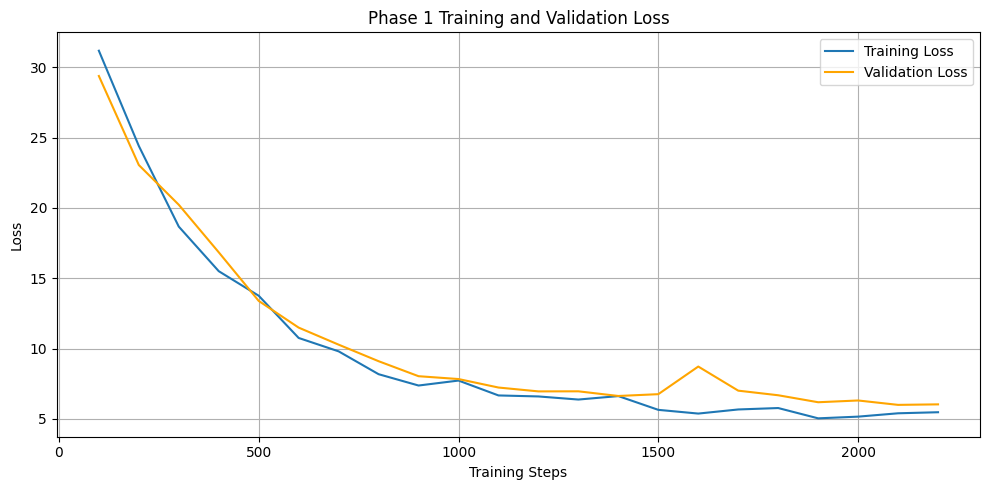

Loss plot saved to: /kaggle/working/cs781_phase1/training_validation_loss.png


In [53]:

# ==========================================
# 6. Generate and Save Loss Plot
# ==========================================
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")

if len(val_steps) > 0 and len(val_loss) > 0:
    plt.plot(val_steps, val_loss, label="Validation Loss", color='orange')

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print(f"Loss plot saved to: {LOSS_PLOT_PATH}")

In [ ]:
# import matplotlib.pyplot as plt

# plt.figure(figsize=(10, 5))
# plt.plot(train_steps, train_loss, label="Training Loss")

# # Only plot validation if we recorded it
# if len(val_steps) > 0 and len(val_loss) > 0:
#     plt.plot(val_steps, val_loss, label="Validation Loss", color='orange')

# plt.xlabel("Training Steps")
# plt.ylabel("Loss")
# plt.title("Phase 1 Training and Validation Loss")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.savefig(LOSS_PLOT_PATH, dpi=200)
# plt.show()

# print("Loss plot saved to:")
# print(LOSS_PLOT_PATH)

In [59]:
# ==========================================
# 6. Test Generation & Submission (KV Cached)
# ==========================================

print("Downloading Test file...")
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO, 
    filename="Phase_1_Pretraining/Test/test.json", 
    repo_type="dataset", 
    token=HF_TOKEN
)
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

predictions = {}

# Extract inner model if wrapped in DataParallel to expose custom forward params
eval_model = model.module if isinstance(model, nn.DataParallel) else model
eval_model.eval()

print("Generating predictions with KV Cache...")
for doc_id, record in tqdm(test_data.items(), desc="Generating"):
    prompt = record["text"]
    input_ids = tokenizer.encode(prompt)
    input_ids = input_ids[-(MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS):]
    input_tensor = torch.tensor([input_ids], dtype=torch.long).to(device)
    
    generated_tokens = []
    word_count = 0  # FIX 3: Initialize fast word tracking
    
    with torch.no_grad():
        with autocast('cuda', dtype=torch.float16):
            # 1. Prompt Phase: Process the entire prompt at once to fill the cache
            logits, kv_caches = eval_model(input_tensor, start_pos=0)
            
        probs = F.softmax(logits[:, -1, :] / TEMPERATURE, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)
        generated_tokens.append(next_token.item())
        
        # Fast incremental space check
        new_token_str = tokenizer.decode([next_token.item()])
        word_count += new_token_str.count(" ")
        
        current_token_tensor = next_token
        current_pos = input_tensor.shape[1]
        
        # 2. Generation Phase: Process ONLY 1 new token per step
        for _ in range(MAX_GENERATION_TOKENS - 1):
            if current_pos >= MODEL_CONTEXT_LENGTH:
                break # Hard stop to avoid out-of-bounds RoPE errors
                
            with autocast('cuda', dtype=torch.float16):
                logits, kv_caches = eval_model(
                    current_token_tensor, 
                    start_pos=current_pos, 
                    kv_caches=kv_caches
                )
                
            probs = F.softmax(logits[:, -1, :] / TEMPERATURE, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
            
            generated_tokens.append(next_token.item())
            current_token_tensor = next_token
            current_pos += 1
            
            # FIX 3: Fast word count check to bypass O(N^2) decoding bottleneck
            new_token_str = tokenizer.decode([next_token.item()])
            word_count += new_token_str.count(" ")
            
            if word_count >= TARGET_GENERATION_WORDS:
                break
                
    # Final exact truncation ensures perfect word count regardless of whitespace formatting
    generated_words = tokenizer.decode(generated_tokens).split()[:TARGET_GENERATION_WORDS]
    predictions[doc_id] = {"text": " ".join(generated_words)}

# Save and Zip
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")

with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:", SUBMISSION_ZIP)

Generating predictions with KV Cache...


Generating: 100%|██████████| 1000/1000 [2:04:51<00:00,  7.49s/it] 

Codabench submission created: /kaggle/working/cs781_phase1/submission.zip


In [ ]:
# # ==========================================
# # 6. Test Generation & Submission (KV Cached)
# # ==========================================
# print("Downloading Test file...")
# test_file_path = hf_hub_download(
#     repo_id=HF_DATASET_REPO, 
#     filename="Phase_1_Pretraining/Test/Phase1-Test.json", 
#     repo_type="dataset", 
#     token=HF_TOKEN
# )
# with open(test_file_path, "r", encoding="utf-8") as f:
#     test_data = json.load(f)

# predictions = {}

# # Extract inner model if wrapped in DataParallel to expose custom forward params
# eval_model = model.module if isinstance(model, nn.DataParallel) else model
# eval_model.eval()

# print("Generating predictions with KV Cache...")
# for doc_id, record in tqdm(test_data.items(), desc="Generating"):
#     prompt = record["text"]
#     input_ids = tokenizer.encode(prompt)
#     input_ids = input_ids[-(MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS):]
#     input_tensor = torch.tensor([input_ids], dtype=torch.long).to(device)
    
#     generated_tokens = []
    
#     with torch.no_grad():
#         with autocast('cuda', dtype=torch.float16):
#             # 1. Prompt Phase: Process the entire prompt at once to fill the cache
#             logits, kv_caches = eval_model(input_tensor, start_pos=0)
            
#         probs = F.softmax(logits[:, -1, :] / TEMPERATURE, dim=-1)
#         next_token = torch.multinomial(probs, num_samples=1)
#         generated_tokens.append(next_token.item())
        
#         # Track our absolute position and the token we are about to pass
#         current_token_tensor = next_token
#         current_pos = input_tensor.shape[1]
        
#         # 2. Generation Phase: Process ONLY 1 new token per step
#         for _ in range(MAX_GENERATION_TOKENS - 1):
#             if current_pos >= MODEL_CONTEXT_LENGTH:
#                 break # Hard stop to avoid out-of-bounds RoPE errors
                
#             with autocast('cuda', dtype=torch.float16):
#                 logits, kv_caches = eval_model(
#                     current_token_tensor, 
#                     start_pos=current_pos, 
#                     kv_caches=kv_caches
#                 )
                
#             probs = F.softmax(logits[:, -1, :] / TEMPERATURE, dim=-1)
#             next_token = torch.multinomial(probs, num_samples=1)
            
#             generated_tokens.append(next_token.item())
#             current_token_tensor = next_token
#             current_pos += 1
            
#             # Efficient whitespace-separated word count check
#             current_words = tokenizer.decode(generated_tokens).split()
#             if len(current_words) >= TARGET_GENERATION_WORDS:
#                 break
                
#     generated_words = tokenizer.decode(generated_tokens).split()[:TARGET_GENERATION_WORDS]
#     predictions[doc_id] = {"text": " ".join(generated_words)}

# # Save and Zip
# PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
# SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")

# with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
#     json.dump(predictions, f, ensure_ascii=False, indent=2)

# with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
#     zipf.write(PREDICTION_PATH, arcname="prediction.json")

# print("Codabench submission created:", SUBMISSION_ZIP)